In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

**Q1**

In [2]:

!pip install -q opencv-python-headless matplotlib numpy scipy


Saving Image to Image


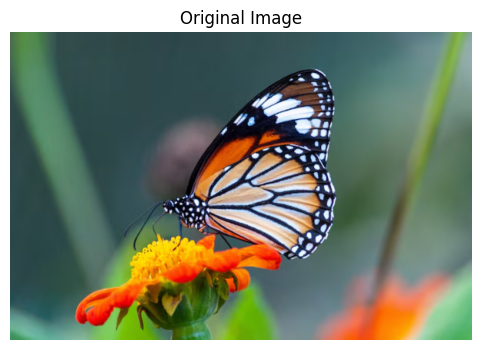

Image shape: (400, 600, 3)


In [3]:

from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

filename = next(iter(uploaded))
image = cv2.imdecode(
    np.frombuffer(uploaded[filename], np.uint8),
    cv2.IMREAD_COLOR
)

if image is None:
    raise ValueError("Could not load the image.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Resize large images for faster processing
image = cv2.resize(image, (600, 400))

plt.figure(figsize=(7, 4))
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)


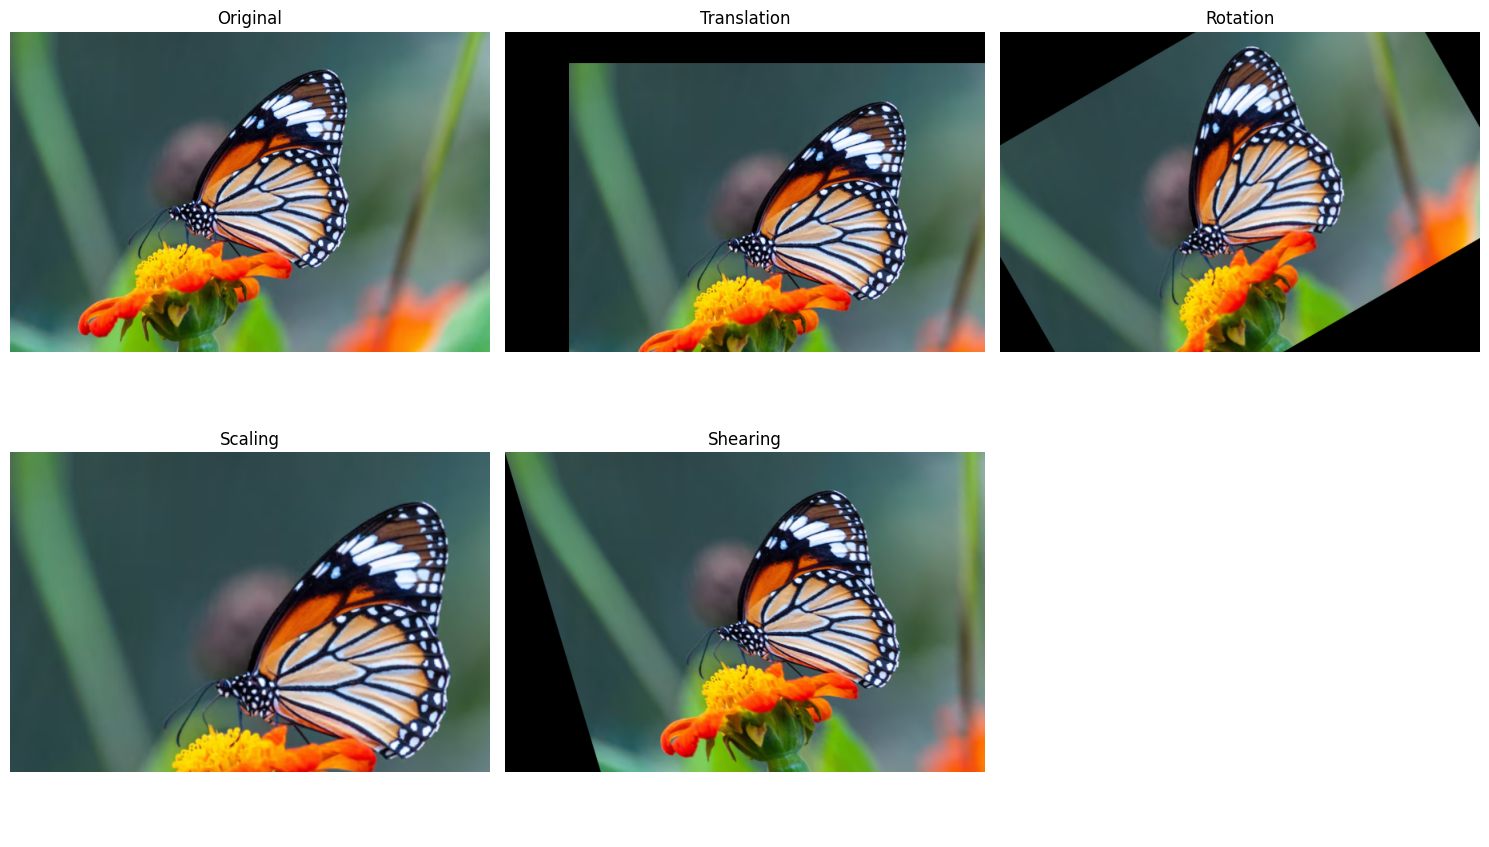

In [4]:

h, w = image.shape[:2]

# 1. Translation: move right and down
T = np.float32([
    [1, 0, 80],
    [0, 1, 40]
])
translated = cv2.warpAffine(image, T, (w, h))

# 2. Rotation: rotate around image center
R = cv2.getRotationMatrix2D((w / 2, h / 2), 30, 1)
rotated = cv2.warpAffine(image, R, (w, h))

# 3. Scaling: enlarge the image
S = cv2.getRotationMatrix2D((0, 0), 0, 1.3)
scaled = cv2.warpAffine(image, S, (w, h))

# 4. Shearing: slant the image horizontally
shear_factor = 0.3
H = np.float32([
    [1, shear_factor, 0],
    [0, 1, 0]
])
sheared = cv2.warpAffine(image, H, (w, h))

# Display all results
results = [
    ("Original", image),
    ("Translation", translated),
    ("Rotation", rotated),
    ("Scaling", scaled),
    ("Shearing", sheared)
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (title, result) in zip(axes.flat, results):
    ax.imshow(result)
    ax.set_title(title)
    ax.axis("off")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


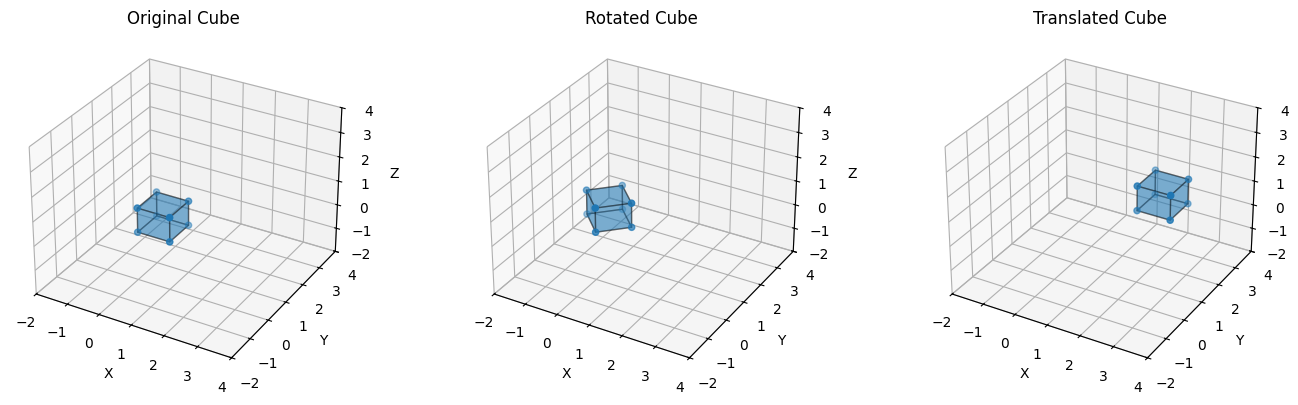

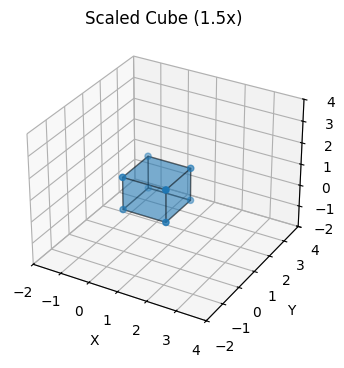

In [5]:

import numpy as np
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Define the 8 vertices of a cube
vertices = np.array([
    [0, 0, 0], [1, 0, 0],
    [1, 1, 0], [0, 1, 0],
    [0, 0, 1], [1, 0, 1],
    [1, 1, 1], [0, 1, 1]
], dtype=float)

faces = [
    [0, 1, 2, 3], [4, 5, 6, 7],
    [0, 1, 5, 4], [2, 3, 7, 6],
    [0, 3, 7, 4], [1, 2, 6, 5]
]

# Rotation around the Z-axis
theta = np.radians(45)
Rz = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta),  np.cos(theta), 0],
    [0, 0, 1]
])

rotated = vertices @ Rz.T

# Scaling
scaled = vertices * 1.5

# Translation
translated = vertices + np.array([2, 1, 1])

def draw_cube(ax, points, title):
    cube_faces = [[points[i] for i in face] for face in faces]
    collection = Poly3DCollection(
        cube_faces, alpha=0.35, edgecolor="black"
    )
    ax.add_collection3d(collection)
    ax.scatter(points[:, 0], points[:, 1], points[:, 2])
    ax.set_xlim(-2, 4)
    ax.set_ylim(-2, 4)
    ax.set_zlim(-2, 4)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title(title)

fig = plt.figure(figsize=(14, 4))

draw_cube(fig.add_subplot(131, projection="3d"),
          vertices, "Original Cube")
draw_cube(fig.add_subplot(132, projection="3d"),
          rotated, "Rotated Cube")
draw_cube(fig.add_subplot(133, projection="3d"),
          translated, "Translated Cube")

plt.tight_layout()
plt.show()

# Show scaling separately
fig = plt.figure(figsize=(5, 4))
draw_cube(fig.add_subplot(111, projection="3d"),
          scaled, "Scaled Cube (1.5x)")
plt.show()


In [6]:

import numpy as np

# A 2D point
x, y = 3, 4

# Convert to homogeneous coordinates
point = np.array([x, y, 1])

print("Original 2D point:", (x, y))
print("Homogeneous coordinates:", point)

# Translation using a 3x3 matrix
T = np.array([
    [1, 0, 5],
    [0, 1, 2],
    [0, 0, 1]
])

new_point = T @ point

# Convert back to ordinary 2D coordinates
x_new = new_point[0] / new_point[2]
y_new = new_point[1] / new_point[2]

print("Transformed homogeneous point:", new_point)
print("Transformed 2D point:", (x_new, y_new))


Original 2D point: (3, 4)
Homogeneous coordinates: [3 4 1]
Transformed homogeneous point: [8 6 1]
Transformed 2D point: (np.float64(8.0), np.float64(6.0))


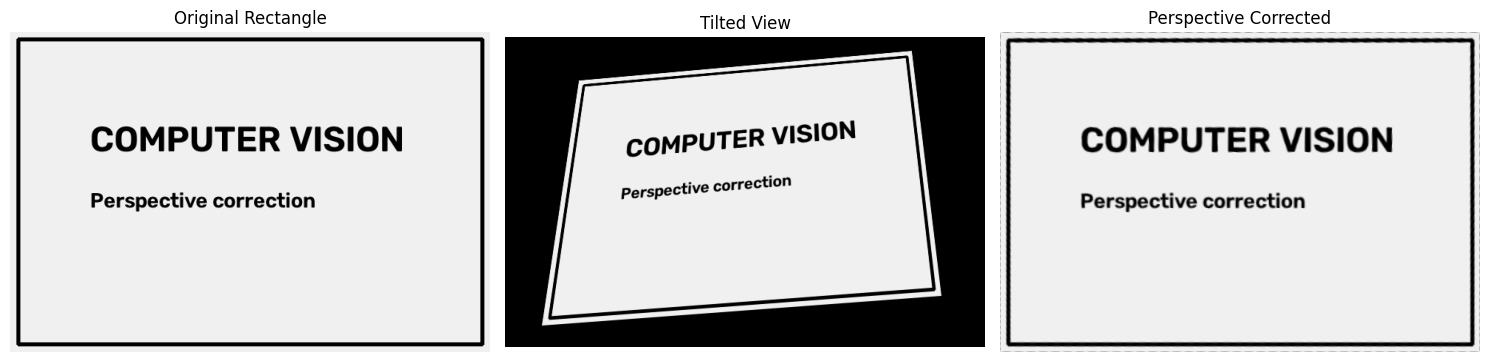

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a sample rectangular document
document = np.ones((400, 600, 3), dtype=np.uint8) * 240

cv2.rectangle(document, (10, 10), (590, 390),
              (0, 0, 0), 3)

cv2.putText(document, "COMPUTER VISION",
            (100, 150), cv2.FONT_HERSHEY_SIMPLEX,
            1.5, (0, 0, 0), 3)

cv2.putText(document, "Perspective correction",
            (100, 220), cv2.FONT_HERSHEY_SIMPLEX,
            0.9, (0, 0, 0), 2)

# Four corners of the original rectangle
src = np.float32([
    [0, 0],
    [599, 0],
    [599, 399],
    [0, 399]
])

# Where those corners appear in a tilted view
dst = np.float32([
    [100, 60],
    [550, 20],
    [590, 350],
    [50, 390]
])

# Transform rectangle into a tilted view
H_tilt = cv2.getPerspectiveTransform(src, dst)
tilted = cv2.warpPerspective(document, H_tilt, (650, 420))

# Map the tilted corners back to a rectangle
rect_src = dst
rect_dst = np.float32([
    [0, 0],
    [599, 0],
    [599, 399],
    [0, 399]
])

H_correct = cv2.getPerspectiveTransform(rect_src, rect_dst)
corrected = cv2.warpPerspective(tilted, H_correct, (600, 400))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(document)
plt.title("Original Rectangle")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(tilted)
plt.title("Tilted View")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(corrected)
plt.title("Perspective Corrected")
plt.axis("off")

plt.tight_layout()
plt.show()
